In [15]:
from google.colab import files

uploaded = files.upload()

Saving drug200[1].csv to drug200[1] (3).csv


In [16]:
import pandas as pd

df = pd.read_csv("drug200[1].csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (200, 6)


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


In [17]:
df.shape

(200, 6)

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


In [19]:
df.isnull().sum()

,0
Age,0
Sex,0
BP,0
Cholesterol,0
Na_to_K,0
Drug,0


In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
# 1. Summary statistics
print("SUMMARY STATISTICS")
display(df.describe())

# 2. Count values in categorical columns
print("\nSEX DISTRIBUTION")
display(df["Sex"].value_counts())

print("\nBLOOD PRESSURE DISTRIBUTION")
display(df["BP"].value_counts())

print("\nCHOLESTEROL DISTRIBUTION")
display(df["Cholesterol"].value_counts())

# 3. Check the target classes
print("\nDRUG CLASS DISTRIBUTION")
display(df["Drug"].value_counts())

# 4. Check the dataset again
print("\nDATASET SHAPE:", df.shape)

SUMMARY STATISTICS


,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000



SEX DISTRIBUTION


,count
Sex,
M,104
F,96



BLOOD PRESSURE DISTRIBUTION


...


CHOLESTEROL DISTRIBUTION


,count
Cholesterol,
HIGH,103
NORMAL,97



DRUG CLASS DISTRIBUTION


,count
Drug,
drugY,91
drugX,54
drugA,23
drugC,16
drugB,16



DATASET SHAPE: (200, 6)


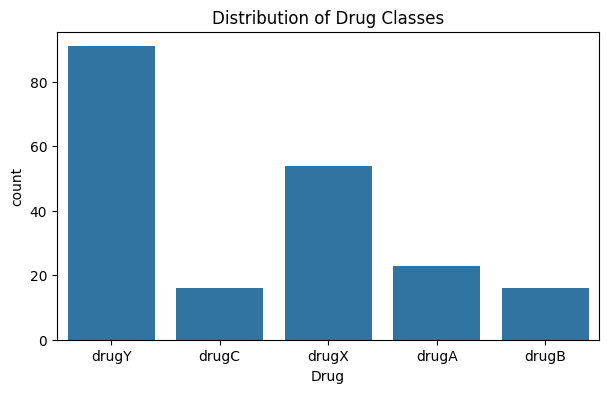

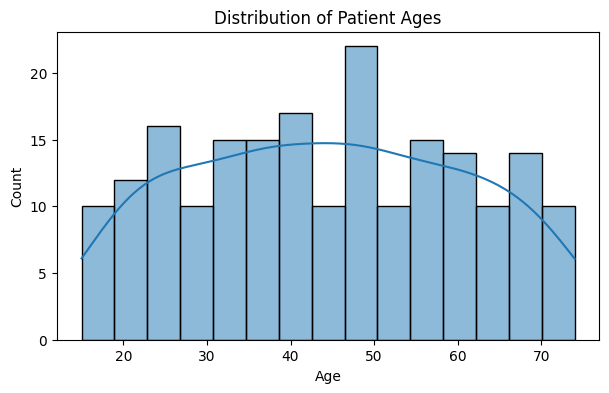

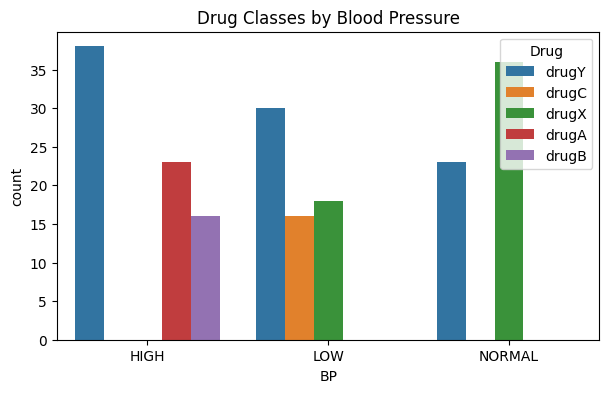

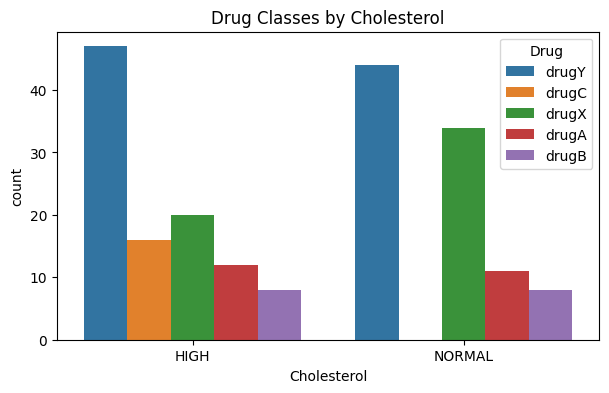

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Distribution of drug classes
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Drug")
plt.title("Distribution of Drug Classes")
plt.show()

# 2. Age distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Age", bins=15, kde=True)
plt.title("Distribution of Patient Ages")
plt.show()

# 3. Drug classes by blood pressure
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="BP", hue="Drug")
plt.title("Drug Classes by Blood Pressure")
plt.show()

# 4. Drug classes by cholesterol
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Cholesterol", hue="Drug")
plt.title("Drug Classes by Cholesterol")
plt.show()

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Separate input features and target
X = df.drop("Drug", axis=1)
y = df["Drug"]

# Encode categorical input columns
X = pd.get_dummies(
    X,
    columns=["Sex", "BP", "Cholesterol"],
    dtype=int
)

# Encode target drug labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Original dataset shape:", df.shape)
print("Processed features shape:", X.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Drug label mapping:")

for number, drug in enumerate(label_encoder.classes_):
    print(number, "=", drug)

Original dataset shape: (200, 6)
Processed features shape: (200, 9)
Training features: (160, 9)
Testing features: (40, 9)
Drug label mapping:
0 = drugA
1 = drugB
2 = drugC
3 = drugX
4 = drugY


In [24]:

import pandas as pd

from sklearn.metrics import accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "SVM": SVC(),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        )
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "Macro F1", ascending=False
)

display(results_df)


,Model,Accuracy,Macro F1
0,Logistic Regression,0.975,0.941818
2,Random Forest,0.975,0.941818
3,Gradient Boosting,0.925,0.825152
1,SVM,0.675,0.304615


In [25]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, f1_score

extra_models = {
    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        random_state=42,
        eval_metric="mlogloss"
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        random_state=42,
        verbosity=-1
    )
}

extra_results = []

for name, model in extra_models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    extra_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        )
    })

extra_df = pd.DataFrame(extra_results)
display(extra_df)

,Model,Accuracy,Macro F1
0,XGBoost,0.925,0.849048
1,LightGBM,0.975,0.949206


In [26]:

import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "SVM": SVC(),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100, max_depth=3,
        learning_rate=0.1, random_state=42,
        eval_metric="mlogloss"
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=100, max_depth=3,
        learning_rate=0.1, random_state=42,
        verbosity=-1
    )
}

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro"
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring=scoring
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "Std CV Accuracy": scores["test_accuracy"].std(),
        "Mean CV Macro F1": scores["test_macro_f1"].mean()
    })

cv_df = pd.DataFrame(cv_results).sort_values(
    "Mean CV Macro F1", ascending=False
)

display(cv_df.round(4))


,Model,Mean CV Accuracy,Std CV Accuracy,Mean CV Macro F1
2,Random Forest,1.0000,0.0000,1.0000
5,LightGBM,0.9875,0.0250,0.9893
3,Gradient Boosting,0.9875,0.0153,0.9835
0,Logistic Regression,0.9812,0.0153,0.9818
4,XGBoost,0.9875,0.0250,0.9804
1,SVM,0.6812,0.0500,0.3097


In [27]:

import pandas as pd

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

rf_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 2]
}

rf_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

print("Random Forest best parameters:")
print(rf_search.best_params_)
print("Best CV Macro F1:", round(rf_search.best_score_, 4))

lgbm_grid = {
    "n_estimators": [50, 100],
    "max_depth": [-1, 3, 5],
    "learning_rate": [0.05, 0.1]
}

lgbm_search = GridSearchCV(
    LGBMClassifier(random_state=42, verbosity=-1),
    lgbm_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

lgbm_search.fit(X_train, y_train)

print("\nLightGBM best parameters:")
print(lgbm_search.best_params_)
print("Best CV Macro F1:", round(lgbm_search.best_score_, 4))


Random Forest best parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV Macro F1: 1.0

LightGBM best parameters:
{'learning_rate': 0.1, 'max_depth': -1, 'n_estimators': 50}
Best CV Macro F1: 0.9965


In [36]:
X_raw = df.drop(columns=["Drug"]).copy()
y_raw = df["Drug"].copy()

In [37]:
print(df.columns.tolist())

['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K', 'Drug']


Final Test Accuracy: 0.975
Final Test Macro F1: 0.9418

Classification Report:
              precision    recall  f1-score   support

           0       0.83      1.00      0.91         5
           1       1.00      0.67      0.80         3
           2       1.00      1.00      1.00         3
           3       1.00      1.00      1.00        11
           4       1.00      1.00      1.00        18

    accuracy                           0.97        40
   macro avg       0.97      0.93      0.94        40
weighted avg       0.98      0.97      0.97        40



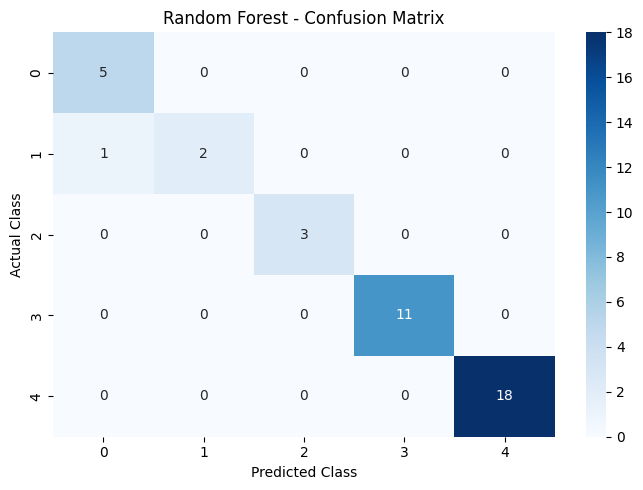

In [38]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Use the best tuned Random Forest
best_rf = rf_search.best_estimator_

# Predict on the held-out test set
y_pred = best_rf.predict(X_test)

print("Final Test Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Final Test Macro F1:",
      round(f1_score(y_test, y_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


In [29]:
import joblib

joblib.dump(
    rf_search.best_estimator_,
    "random_forest_checkpoint.pkl"
)

print("Checkpoint saved!")

Checkpoint saved!


In [30]:
from google.colab import files

files.download("random_forest_checkpoint.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTraining feature columns:")
print(list(X_train.columns)
      if hasattr(X_train, "columns")
      else "X_train is a NumPy array")

print("\nTarget encoder or label mapping variables:")
for name in ["label_encoder", "le", "encoder", "target_encoder"]:
    if name in globals():
        print(name, "=", globals()[name])

X_train shape: (160, 9)
X_test shape: (40, 9)

Training feature columns:
['Age', 'Na_to_K', 'Sex_F', 'Sex_M', 'BP_HIGH', 'BP_LOW', 'BP_NORMAL', 'Cholesterol_HIGH', 'Cholesterol_NORMAL']

Target encoder or label mapping variables:
label_encoder = LabelEncoder()


In [39]:

import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Separate raw features and target
X_raw = df.drop(columns=["Drug"]).copy()
y_raw = df["Drug"].copy()

# Define preprocessing
numeric_features = ["Age", "Na_to_K"]
categorical_features = ["Sex", "BP", "Cholesterol"]

preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

# Complete preprocessing + model pipeline
pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

# Fresh stratified split
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw,
    test_size=0.2,
    random_state=42,
    stratify=y_raw
)

# Tune using training data only
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_leaf": [1, 2]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = GridSearchCV(
    pipeline,
    param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

search.fit(X_train_raw, y_train_raw)

# Evaluate on the held-out test set
best_pipeline = search.best_estimator_
y_pred_raw = best_pipeline.predict(X_test_raw)

print("Best parameters:", search.best_params_)
print("Best CV Macro F1:", round(search.best_score_, 4))
print("Test accuracy:", round(accuracy_score(y_test_raw, y_pred_raw), 4))
print("Test macro F1:", round(f1_score(
    y_test_raw, y_pred_raw, average="macro"
), 4))

print("\nClassification report:")
print(classification_report(
    y_test_raw, y_pred_raw, zero_division=0
))

print("Drug classes:", list(best_pipeline.named_steps["model"].classes_))


Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Best CV Macro F1: 1.0
Test accuracy: 0.975
Test macro F1: 0.9418

Classification report:
              precision    recall  f1-score   support

       drugA       0.83      1.00      0.91         5
       drugB       1.00      0.67      0.80         3
       drugC       1.00      1.00      1.00         3
       drugX       1.00      1.00      1.00        11
       drugY       1.00      1.00      1.00        18

    accuracy                           0.97        40
   macro avg       0.97      0.93      0.94        40
weighted avg       0.98      0.97      0.97        40

Drug classes: ['drugA', 'drugB', 'drugC', 'drugX', 'drugY']


In [40]:

import joblib

# Save the complete preprocessing + model pipeline
joblib.dump(
    best_pipeline,
    "drug_classification_pipeline.joblib"
)

print("Pipeline saved successfully!")


Pipeline saved successfully!


In [41]:
from google.colab import files

files.download("drug_classification_pipeline.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:

import joblib
import pandas as pd

loaded_pipeline = joblib.load(
    "drug_classification_pipeline.joblib"
)

sample = pd.DataFrame([{
    "Age": 30,
    "Sex": "F",
    "BP": "HIGH",
    "Cholesterol": "NORMAL",
    "Na_to_K": 15.0
}])

prediction = loaded_pipeline.predict(sample)

print("Predicted class:", prediction[0])


Predicted class: drugY


In [43]:
import pandas as pd

all_results = pd.concat(
    [results_df, extra_df],
    ignore_index=True
)

all_results = all_results.sort_values(
    "Macro F1", ascending=False
)

display(all_results)

all_results.to_csv("model_comparison.csv", index=False)

,Model,Accuracy,Macro F1
5,LightGBM,0.975,0.949206
0,Logistic Regression,0.975,0.941818
1,Random Forest,0.975,0.941818
4,XGBoost,0.925,0.849048
2,Gradient Boosting,0.925,0.825152
3,SVM,0.675,0.304615


In [44]:
from google.colab import files

files.download("model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>